# List 1: PyTorch & Training Fundamentals

Labs: Mon 5 Oct, Mon 12 Oct 2026 · Due: Sun 18 Oct 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the four given functions, because later lists reuse them (check them with Materials, Appendix A).
- Background and the PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Individual work. Name the AI tools you used at the top of your solution.

In [1]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader

## Lab 1

### 1.1 Tensors

- Write down the expected shapes of five operations (covering reshape, transpose, `@`, `*` and broadcasting, one of them a broadcast that fails), then run them. Explain the failure.
- Show a case where `view` fails and `reshape` works, and explain it with strides.
- Show a computation that `float32` gets wrong and `float64` gets right.
- Convert an array from NumPy to PyTorch and back. Show which conversions share memory, and which dtype each library uses by default.

In [2]:
A=torch.arange(12)
print(20*"=", "A" , 20*"=","\n")
print(A)
print(A.shape)

B=A.reshape(3,4)
print("\n", 20*"=", "B, reshape" , 20*"=","\n")
print(B)
print("Expected shape is 3x4")
print(B.shape)

C=B.T
print("\n", 20*"=", "C, transpose" , 20*"=","\n")
print(C)
print("Expected shape is 4x3")
print(C.shape)

D=B@C
print("\n", 20*"=", "D, @" , 20*"=","\n")
print(D)
print("Expected shape is 3x3")
print(D.shape)

E=D*C[1:,:]
print("\n", 20*"=", "E, *" , 20*"=","\n")
print(E)
print("Expected shape is as the shape of D => 3x3")
print("E: ", E.shape)

print("\n", 20*"=", "Broadcasting" , 20*"=","\n")
x = torch.zeros(4, 1, 3)
y = torch.zeros(5, 1)
print("Expected shape is (4,5,3)")
print((x + y).shape)

print("\n", 20*"=", "Broadcasting failure" , 20*"=","\n") 
X = torch.zeros(4, 2, 3)
Y = torch.zeros(5, 2)

print("Expected is error")

try:
    print((X + Y).shape)
except RuntimeError as e:
    print("Broadcasting failed:", e)
    print("""Broadcasting fails because the tensor dimensions are incompatible and neither dimension is 1.""")

==================== A ==================== 

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
torch.Size([12])

 ==================== B, reshape ==================== 

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Expected shape is 3x4
torch.Size([3, 4])

 ==================== C, transpose ==================== 

tensor([[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]])
Expected shape is 4x3
torch.Size([4, 3])

 ==================== D, @ ==================== 

tensor([[ 14,  38,  62],
        [ 38, 126, 214],
        [ 62, 214, 366]])
Expected shape is 3x3
torch.Size([3, 3])

 ==================== E, * ==================== 

tensor([[  14,  190,  558],
        [  76,  756, 2140],
        [ 186, 1498, 4026]])
Expected shape is as the shape of D => 3x3
E:  torch.Size([3, 3])

 ==================== Broadcasting ==================== 

Expected shape is (4,5,3)
torch.Size([4, 5, 3])

 ==================== Broadcasting f

In [3]:
A = torch.arange(12).reshape(3, 4)
B = A.T

print("A strides:", A.stride())
print("B strides:", B.stride())
print("B is contiguous:", B.is_contiguous())

try:
    print(B.view(-1))
except RuntimeError as e:
    print("View failed:", e)

print("Reshape result:", B.reshape(-1))

A strides: (4, 1)
B strides: (1, 4)
B is contiguous: False
View failed: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.
Reshape result: tensor([ 0,  4,  8,  1,  5,  9,  2,  6, 10,  3,  7, 11])


After transposing, the numbers are read in a different order, but their order in memory does not change. Using `view()`, we want to represent tensor B as a one-dimensional vector. However, the jumps between consecutive elements in memory would be different, so the vector cannot be represented using one constant stride. Therefore, `view()` fails, while `reshape()` works because it can create a copy of the data in memory and arrange the elements in the correct order.

In [4]:
for dt in [torch.float32, torch.float64]:
    x = torch.tensor(1e8, dtype=dt)
    result = (x + 1) - x

    print(dt, "Result:", result.item())

torch.float32 Result: 0.0
torch.float64 Result: 1.0


The expected result is 1, but `float32` returns 0 because it has lower precision and cannot represent the difference between 100000000 and 100000001. `float64` has higher precision, so it correctly returns 1.

In [5]:
import numpy as np

print("==========Convert from Numpy to Torch==========")
a = np.array([1.0, 2.0, 3.0])
b = torch.from_numpy(a)
c = torch.tensor(a)
d = torch.tensor([1.0, 2.0, 3.0])


print("a: ", a, "dtype: ", a.dtype)
print("b: ", b, "dtype: ", b.dtype)
print("c: ", c, "dtype: ", c.dtype)
print("d: ", d, "dtype: ", d.dtype)


print("\n")
print("==========Changing elements in a and b==========")
a[0]=10
b[0]=100
print("a: ", a, "dtype: ", a.dtype)
print("b: ", b, "dtype: ", b.dtype)
print("c: ", c, "dtype: ", c.dtype)
print("d: ", d, "dtype: ", d.dtype)


print("\n")
print("==========Convert from Torch to Numpy==========")
e = b.numpy()
e[1] = 200

print("a: ", a, "dtype: ", a.dtype)
print("b: ", b, "dtype: ", b.dtype)
print("c: ", c, "dtype: ", c.dtype)
print("d: ", d, "dtype: ", d.dtype)
print("e: ", e, "dtype: ", e.dtype)


==========Convert from Numpy to Torch==========
a:  [1. 2. 3.] dtype:  float64
b:  tensor([1., 2., 3.], dtype=torch.float64) dtype:  torch.float64
c:  tensor([1., 2., 3.], dtype=torch.float64) dtype:  torch.float64
d:  tensor([1., 2., 3.]) dtype:  torch.float32


==========Changing elements in a and b==========
a:  [100.   2.   3.] dtype:  float64
b:  tensor([100.,   2.,   3.], dtype=torch.float64) dtype:  torch.float64
c:  tensor([1., 2., 3.], dtype=torch.float64) dtype:  torch.float64
d:  tensor([1., 2., 3.]) dtype:  torch.float32


==========Convert from Torch to Numpy==========
a:  [100. 200.   3.] dtype:  float64
b:  tensor([100., 200.,   3.], dtype=torch.float64) dtype:  torch.float64
c:  tensor([1., 2., 3.], dtype=torch.float64) dtype:  torch.float64
d:  tensor([1., 2., 3.]) dtype:  torch.float32
e:  [100. 200.   3.] dtype:  float64


NumPy uses `float64` by default, while PyTorch uses `float32`. When converting a NumPy array to PyTorch, the original dtype is kept. `torch.from_numpy()` shares memory with the original array, so changing elements in `a` or `b` changes both, while `torch.tensor()` creates a separate copy. After converting `b` back to NumPy using `.numpy()`, changing elements in `e` also changes `a` and `b` because they share the same memory.

### 1.2 Autograd and a gradient check

One-feature logistic regression with binary cross-entropy: $L = -[\,y \log a + (1-y)\log(1-a)\,]$, $a = \sigma(w_1 x_1 + b)$.

- Compute $\partial L/\partial w_1$ and $\partial L/\partial b$ analytically, with autograd and with central finite differences, in `float64`, and check that they match. Reference: for $x_1 = 1.1$, $w_1 = 2.2$, $b = 0$, $y = 1$, $L \approx 0.0852$ and the gradients are $\approx -0.0898$ and $-0.0817$.
- Plot the error of the finite-difference $\partial L/\partial w_1$ (against the analytic value) for $h = 10^{-1}, \dots, 10^{-12}$ on log–log axes, in `float32` and `float64`. Explain the shape of the curves.
- Call `backward()` on two freshly built losses without resetting `.grad`. Show and explain what happens.

In [6]:
def bce_loss(x1, w1, b, y):
    a = torch.sigmoid(w1*x1+b)
    loss = -(y*torch.log(a) + (1-y)*torch.log(1-a))
    return loss


w1 = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0, dtype=torch.float64, requires_grad=True)
x1, y = 1.1, 1
bce_loss(x1,w1,b,y)


### analytically using chain rule: 
# dL/dw1 = dL/da * da/dz * dz/dw1 = (a-y)*x1 
# dL/db = dL/da* da/dz*dz/db = a-y

with torch.no_grad():
    a = torch.sigmoid(w1*x1 + b)
    grad_w_analytic = ((a-y)*x1).item()
    grad_b_analytic = (a-y).item()

### with autograd in float64
L = bce_loss(x1, w1, b, y)
L.backward()
grad_w_autograd, grad_b_autograd = w1.grad.item(), b.grad.item()

### with central finite differencies in float64
h=1e-6

with torch.no_grad():
    grad_w_fdiff = ((bce_loss(x1, w1+h, b, y) - bce_loss(x1, w1-h, b, y))/(2*h)).item()
    grad_b_fdiff = ((bce_loss(x1, w1, b+h, y) - bce_loss(x1, w1, b-h, y))/(2*h)).item()


print(f"L={L:.4f}")
print(f"""
given: 
    dL/dw1 = {-0.0898}, dL/db={-0.0817},
analytically:
    dL/dw1 = {grad_w_analytic:.5f}, dL/db={grad_b_analytic:.5f},
with autograd:
    dL/dw1 = {grad_w_autograd:.5f}, dL/db={grad_b_autograd:.5f},
finite differencies:
    dL/dw1={grad_w_fdiff:.5f}, dL/db={grad_b_fdiff:.5f}
""")

analytic = torch.tensor([grad_w_analytic, grad_b_analytic], dtype=torch.float64)
print("autograd  == analytic:", torch.allclose(torch.tensor([grad_w_autograd, grad_b_autograd], dtype=torch.float64), analytic))
print("finite diffrencies ~= analytic:", torch.allclose(torch.tensor([grad_w_fdiff, grad_b_fdiff], dtype=torch.float64), analytic, atol=1e-8))

L=0.0852

given: 
    dL/dw1 = -0.0898, dL/db=-0.0817,
analytically:
    dL/dw1 = -0.08983, dL/db=-0.08166,
with autograd:
    dL/dw1 = -0.08983, dL/db=-0.08166,
finite differencies:
    dL/dw1=-0.08983, dL/db=-0.08166

autograd  == analytic: True
finite diffrencies ~= analytic: True


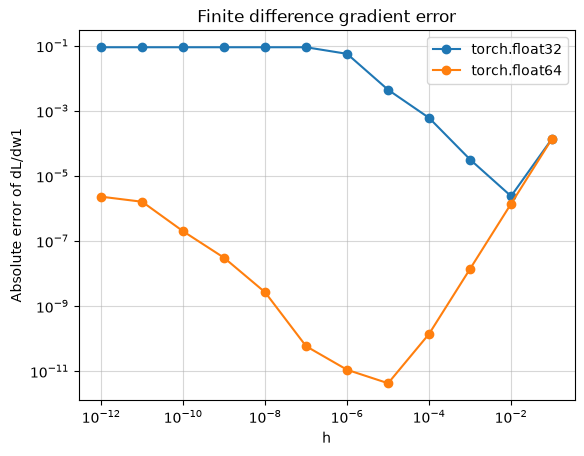

In [7]:
import matplotlib.pyplot as plt


hs = 10.0 ** -np.arange(1, 13)

for dt in [torch.float32, torch.float64]:
    w = w1.detach().to(dt)
    bias = b.detach().to(dt)

    errors = []

    for h in hs:
        with torch.no_grad():
            grad_w_fdiff = (
                (bce_loss(x1, w+h, bias, y) - bce_loss(x1, w-h, bias, y))/(2*h)).item()

        error = abs(grad_w_fdiff - grad_w_analytic)
        errors.append(error)

    plt.loglog(hs, errors, "o-", label=str(dt))

plt.xlabel("h")
plt.ylabel("Absolute error of dL/dw1")
plt.title("Finite difference gradient error")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

The truncation error of central finite differences is O(h²), so the error initially decreases as h becomes smaller. However, when h is very small, rounding errors become dominant because we subtract two nearly equal numbers, which leads to a loss of numerical precision. On the plot, float64 achieves the smallest error around h = 1e-5, while float32 starts losing accuracy much earlier due to its lower precision. For very small values of h, the float32 error becomes almost constant because the changes are too small to be represented. This shows that decreasing h does not always improve the accuracy of the approximation.

In [8]:
w1.grad = None
b.grad = None

# First loss
L1 = bce_loss(x1, w1, b, y)
L1.backward()

print("After first backward():")
print("dL/dw1 =", w1.grad.item())
print("dL/db  =", b.grad.item())

# Second loss without resetting gradients
L2 = bce_loss(x1, w1, b, y)
L2.backward()

print("\nAfter second backward():")
print("dL/dw1 =", w1.grad.item())
print("dL/db  =", b.grad.item())

After first backward():
dL/dw1 = -0.08982628100775408
dL/db  = -0.08166025546159461

After second backward():
dL/dw1 = -0.17965256201550817
dL/db  = -0.16332051092318922


After the first `backward()`, the gradients are stored in `.grad`. When we call `backward()` again without resetting `.grad`, the new gradients are added to the previous ones, so the values double because both losses are the same.

### 1.3 Linear regression

Default data: $N = 200$, $d = 3$, $\mathbf{x} \sim \mathcal{N}(\mathbf{0}, \operatorname{diag}(1, 4, 0.25))$, $y = \mathbf{w}^{\ast\top}\mathbf{x} + b^\ast + 0.1\,\varepsilon$ with $\mathbf{w}^\ast, b^\ast$ of your choice.

- Minimise the mean squared error by least squares, and by full-batch gradient descent twice: in NumPy with the gradient derived by hand, and in PyTorch with autograd and `torch.optim.SGD`. Compare the three solutions.
- Find the largest learning rate for which the loss still decreases over 300 steps, experimentally (two significant digits) and from the Hessian. Compare.

In [9]:
np.random.seed(42)

N = 200
d = 3

X = np.random.randn(N, d) * np.array([1.0, 2.0, 0.5])

w_true = np.array([1.5, -2.0, 0.8])
b_true = 0.5

epsilon = np.random.randn(N)
y = X @ w_true + b_true + 0.1 * epsilon

print("X shape:", X.shape)
print("y shape:", y.shape)
print("True weights:", w_true)
print("True bias:", b_true)

X shape: (200, 3)
y shape: (200,)
True weights: [ 1.5 -2.   0.8]
True bias: 0.5


In [10]:
### Least squares ###
print("\n========== Least squares ==========")

X_new = np.column_stack((X, np.ones(N)))

theta_ls = np.linalg.lstsq(X_new, y, rcond=None)[0]

w_ls = theta_ls[:3]
b_ls = theta_ls[3]

mse_ls = np.mean((X_new @ theta_ls - y)**2)

print("Weights:", w_ls)
print("Bias:", b_ls)
print("MSE:", mse_ls)


========== Least squares ==========
Weights: [ 1.49761626 -1.99538152  0.82370895]
Bias: 0.501882387655862
MSE: 0.010125328744707921


In [11]:
###Gradient descent in NumPy ###
print("\n========== Gradient descent in NumPy ==========")

theta_np = np.zeros(d + 1)

lr = 0.1
epochs = 1000

for i in range(epochs):
    predictions = X_new @ theta_np
    error = predictions - y

    grad = (2 / N) * X_new.T @ error

    theta_np = theta_np - lr * grad

w_np = theta_np[:3]
b_np = theta_np[3]

mse_np = np.mean((X_new @ theta_np - y)**2)

print("Weights:", w_np)
print("Bias:", b_np)
print("MSE:", mse_np)


========== Gradient descent in NumPy ==========
Weights: [ 1.49761626 -1.99538152  0.82370895]
Bias: 0.5018823876558632
MSE: 0.010125328744707918


In [12]:
### Gradient descent in PyTorch ###
print("\n========== Gradient descent in PyTorch ==========")

X_torch = torch.tensor(X_new, dtype=torch.float64)
y_torch = torch.tensor(y, dtype=torch.float64)

theta_torch = torch.zeros(d + 1, dtype=torch.float64, requires_grad=True)

optimizer = torch.optim.SGD([theta_torch], lr=lr)

for i in range(epochs):
    predictions = X_torch @ theta_torch
    loss = ((predictions - y_torch)**2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

w_torch = theta_torch.detach().numpy()[:3]
b_torch = theta_torch.detach().numpy()[3]

mse_torch = ((X_torch @ theta_torch - y_torch)**2).mean().item()

print("Weights:", w_torch)
print("Bias:", b_torch)
print("MSE:", mse_torch)


========== Gradient descent in PyTorch ==========
Weights: [ 1.49761626 -1.99538152  0.82370895]
Bias: 0.5018823876558632
MSE: 0.010125328744707918


In [13]:
### Compare results ###
print("\n========== Comparison ==========")

print(f"{'Method':<18} {'w1':>12} {'w2':>12} {'w3':>12} {'bias':>12}")
print("-" * 70)

for name, w, bias in [
    ("True values", w_true, b_true),
    ("Least squares", w_ls, b_ls),
    ("NumPy GD", w_np, b_np),
    ("PyTorch SGD", w_torch, b_torch)
]:
    print(f"{name:<18} {w[0]:>12.6f} {w[1]:>12.6f} {w[2]:>12.6f} {bias:>12.6f}")


print("\n========== MSE comparison ==========")

print(f"{'Least squares':<18} {mse_ls:.8f}")
print(f"{'NumPy GD':<18} {mse_np:.8f}")
print(f"{'PyTorch SGD':<18} {mse_torch:.8f}")

print("\nNumPy GD ~= Least squares:",
      np.allclose(theta_np, theta_ls, atol=1e-5))

print("PyTorch SGD ~= Least squares:",
      np.allclose(theta_torch.detach().numpy(), theta_ls, atol=1e-5))


========== Comparison ==========
Method                       w1           w2           w3         bias
----------------------------------------------------------------------
True values            1.500000    -2.000000     0.800000     0.500000
Least squares          1.497616    -1.995382     0.823709     0.501882
NumPy GD               1.497616    -1.995382     0.823709     0.501882
PyTorch SGD            1.497616    -1.995382     0.823709     0.501882

========== MSE comparison ==========
Least squares      0.01012533
NumPy GD           0.01012533
PyTorch SGD        0.01012533

NumPy GD ~= Least squares: True
PyTorch SGD ~= Least squares: True


All three methods give very similar results, with almost identical weights, bias and MSE values. The NumPy and PyTorch gradient descent methods converge to the least squares solution because they use the same starting values, learning rate and gradient updates. The estimated parameters are close to the true values, but slightly different because of the added random noise. The MSE is a convex quadratic function, so gradient descent can converge to its global minimum.

In [14]:
def gradient_descent(lr):
    theta = np.zeros(X_new.shape[1])
    losses = []

    for i in range(300):
        error = X_new @ theta - y
        loss = np.mean(error**2)
        losses.append(loss)

        grad = (2 / N) * X_new.T @ error
        theta = theta - lr * grad

    return np.array(losses)

### Largest learning rate experimentally ###
print("========== Experimental learning rate ==========")

learning_rates = np.arange(0.01, 0.51, 0.0001)
valid_rates = []

for lr in learning_rates:
    losses = gradient_descent(lr)

    if np.all(np.isfinite(losses)) and np.all(np.diff(losses) <= 1e-10):
        valid_rates.append(lr)

lr_experimental = max(valid_rates)

print(f"Largest experimental learning rate: {lr_experimental:.2g}")

========== Experimental learning rate ==========
Largest experimental learning rate: 0.24


In [15]:
### Largest learning rate from Hessian ###
print("\n========== Learning rate from Hessian ==========")

H = (2 / N) * X_new.T @ X_new

eigenvalues = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalues)

lr_hessian = 2 / lambda_max

print("Hessian eigenvalues:", eigenvalues)
print(f"Largest eigenvalue: {lambda_max:.6f}")
print(f"Maximum theoretical learning rate: {lr_hessian:.6f}")


========== Learning rate from Hessian ==========
Hessian eigenvalues: [0.49868291 1.5532206  1.98950553 8.25098631]
Largest eigenvalue: 8.250986
Maximum theoretical learning rate: 0.242395


In [16]:
### Comparison ###
print("\n========== Comparison ==========")

print(f"{'Experimental':<20} {lr_experimental:.6f}")
print(f"{'From Hessian':<20} {lr_hessian:.6f}")
print(f"{'Difference':<20} {abs(lr_experimental - lr_hessian):.6f}")


========== Comparison ==========
Experimental         0.242300
From Hessian         0.242395
Difference           0.000095


The largest experimental learning rate is close to the theoretical limit calculated from the Hessian, using the formula $\eta = 2/\lambda_{max}$. For learning rates below this limit, the MSE decreases during gradient descent. When the learning rate is too large, the updates become unstable and the loss may increase instead of decreasing. The small difference between the experimental and theoretical results is caused by testing a finite set of learning rates.

### 1.4 A multilayer network

- Implement `count_parameters` and an MLP as an `nn.Module` built from a list of layer sizes, with ReLU between layers. For sizes `[50, 30, 20, 3]`, check the count (2213) against a sum written by hand.
- Implement a softmax without `torch.softmax` that stays finite for the logits `[1000., 1001., 999.]`.

In [17]:
def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    """Number of (trainable) scalar parameters of `model`."""
    if trainable_only:
        return sum(p.numel() for p in model.parameters() if p.requires_grad)
    return sum(p.numel() for p in model.parameters())

In [18]:
# ---------- MLP model ----------
class MLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()

        layers = []

        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i + 1]))

            if i < len(sizes) - 2:
                layers.append(nn.ReLU())

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [19]:
# ---------- Create model ----------
sizes = [50, 30, 20, 3]
model = MLP(sizes)

print("========== MLP model ==========")
print(model)


# ---------- Count parameters ----------
print("\n========== Parameter count ==========")

for name, p in model.named_parameters():
    print(f"{name:<22} {str(tuple(p.shape)):<12} {p.numel():>6}")

print("\nTotal parameters:", count_parameters(model))


# ---------- Manual calculation ----------
print("\n========== Manual calculation ==========")

manual_count = 0

for i in range(len(sizes) - 1):
    weights = sizes[i] * sizes[i + 1]
    biases = sizes[i + 1]

    manual_count += weights + biases

    print(f"Layer {i+1}: {weights} + {biases} = {weights + biases}")

print("\nManual count:", manual_count)
print("Counts match:", count_parameters(model) == manual_count)
print("Expected count is 2213:", count_parameters(model) == 2213)

========== MLP model ==========
MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)

========== Parameter count ==========
net.0.weight           (30, 50)       1500
net.0.bias             (30,)            30
net.2.weight           (20, 30)        600
net.2.bias             (20,)            20
net.4.weight           (3, 20)          60
net.4.bias             (3,)              3

Total parameters: 2213

========== Manual calculation ==========
Layer 1: 1500 + 30 = 1530
Layer 2: 600 + 20 = 620
Layer 3: 60 + 3 = 63

Manual count: 2213
Counts match: True
Expected count is 2213: True


The MLP consists of three linear layers with ReLU activation between them. Each linear layer has d_in × d_out weights and d_out biases, while ReLU has no trainable parameters. The total number of parameters is 1530 + 620 + 63 = 2213, which matches the result calculated using `count_parameters()`.

In [20]:
# ---------- Stable softmax ----------
print("========== Stable softmax ==========")

logits = torch.tensor([1000., 1001., 999.])

# Subtract the maximum value
z = logits - logits.max()

# Calculate softmax
exp_z = torch.exp(z)
softmax = exp_z / exp_z.sum()

print("Original logits:", logits)
print("Shifted logits:", z)
print("Softmax:", softmax)
print("Sum:", softmax.sum().item())
print("All finite:", torch.isfinite(softmax).all().item())

========== Stable softmax ==========
Original logits: tensor([1000., 1001.,  999.])
Shifted logits: tensor([-1.,  0., -2.])
Softmax: tensor([0.2447, 0.6652, 0.0900])
Sum: 1.0
All finite: True


Calculating softmax directly for large logits can cause overflow because the exponential values become too large. To avoid this, we subtract the maximum logit before calculating the exponentials. This does not change the probabilities, but keeps the results finite. The calculated probabilities sum to 1.

## Lab 2

### 2.1 `Dataset` and `DataLoader`

Default data: four classes in the plane, 150 points each, centres $(\pm 2, \pm 2)$, $\mathbf{x} = \boldsymbol\mu_c + 0.9\,\boldsymbol\epsilon$.

- Write a `Dataset`, split it 60/20/20 with a fixed seed, and build the three `DataLoader`s. Explain why only the training loader is shuffled.

In [21]:
from torch.utils.data import Dataset, DataLoader, random_split

# ---------- Generate data ----------
torch.manual_seed(42)

n = 150
centers = torch.tensor([
    [-2., -2.],
    [-2.,  2.],
    [ 2., -2.],
    [ 2.,  2.]
])

X = torch.cat([center + 0.9 * torch.randn(n, 2)
               for center in centers])

y = torch.arange(4).repeat_interleave(n)

print("========== Generated data ==========")
print("X shape:", X.shape)
print("y shape:", y.shape)

========== Generated data ==========
X shape: torch.Size([600, 2])
y shape: torch.Size([600])


In [22]:
# ---------- Dataset ----------
class PointsDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


dataset = PointsDataset(X, y)

print("\n========== Dataset ==========")
print("Number of samples:", len(dataset))
print("First sample:", dataset[0])


========== Dataset ==========
Number of samples: 600
First sample: (tensor([-0.2658, -0.6614]), tensor(0))


In [23]:
# ---------- Split data ----------
train_ds, val_ds, test_ds = random_split(
    dataset,
    [0.6, 0.2, 0.2],
    generator=torch.Generator().manual_seed(42)
)

print("\n========== Data split ==========")
print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))


========== Data split ==========
Training samples: 360
Validation samples: 120
Test samples: 120


In [24]:
# ---------- DataLoaders ----------
batch_size = 32

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

print("\n========== DataLoaders ==========")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


========== DataLoaders ==========
Training batches: 12
Validation batches: 4
Test batches: 4


In [25]:
# Check the shape of one batch
features, labels = next(iter(train_loader))

print("\nFirst training batch:")
print("Features shape:", features.shape)
print("Labels shape:", labels.shape)


First training batch:
Features shape: torch.Size([32, 2])
Labels shape: torch.Size([32])


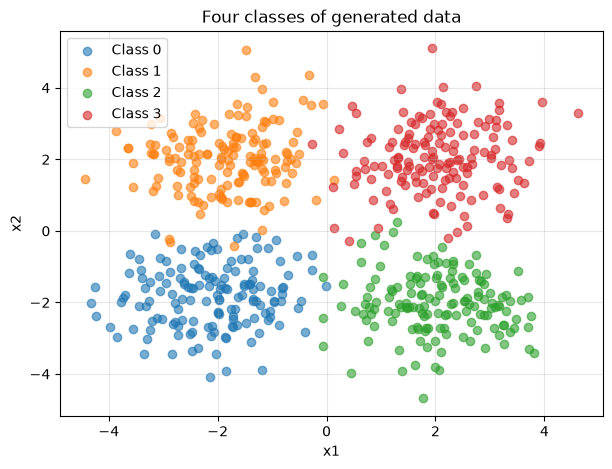

In [26]:
# ---------- Plot generated data ----------
plt.figure(figsize=(7, 5))

for i in range(4):
    points = X[y == i]
    plt.scatter(points[:, 0], points[:, 1], label=f"Class {i}", alpha=0.6)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Four classes of generated data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


The dataset contains 600 points from four classes, with 150 points around each centre. The data was randomly split into training (60%), validation (20%) and test (20%) sets using a fixed seed to make the results reproducible. Only the training DataLoader uses `shuffle=True` to change the order of samples in each epoch and create different batches during training. Validation and test DataLoaders are not shuffled because they are only used to evaluate the model, so changing the order is unnecessary.

### 2.2 The training loop

- Implement `compute_loss`, `compute_accuracy` and `train`.
- Train your MLP once with SGD and once with Adam (default: sizes `[2, 30, 20, 4]`, batch size 32, 30 epochs) and plot both validation-loss curves. Pick the run with the lower final validation loss and report its test accuracy.
- Save its `state_dict`, load it into a new model, and show that it gives the same outputs.

In [27]:
def compute_loss(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Mean cross-entropy over all predictions in `loader`.

    Logits may be (B, C) with targets (B,), or (B, T, C) with targets (B, T).
    """
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)

            # Also works for logits of shape (B, T, C)
            logits = logits.reshape(-1, logits.shape[-1])
            labels = labels.reshape(-1)

            loss = F.cross_entropy(logits, labels, reduction="sum")

            total_loss += loss.item()
            total_samples += labels.numel()

    return total_loss / total_samples

In [28]:
def compute_accuracy(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Fraction of correct argmax predictions over all of `loader`."""
    model.eval()
    correct = 0
    total_samples = 0

    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)
            predictions = logits.argmax(dim=-1)

            correct += (predictions == labels).sum().item()
            total_samples += labels.numel()

    return correct / total_samples

In [29]:

def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    num_epochs: int,
    device: torch.device | str = "cpu",
) -> dict[str, list[float]]:
    """Train with cross-entropy.

    Returns {"train_loss": [...], "val_loss": [...]}, one value per epoch.
    """
    model.to(device)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(num_epochs):
        model.train()

        total_loss = 0.0
        total_samples = 0

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)

            loss = F.cross_entropy(
                logits.reshape(-1, logits.shape[-1]),
                labels.reshape(-1)
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            n = labels.numel()
            total_loss += loss.item() * n
            total_samples += n

        train_loss = total_loss / total_samples
        val_loss = compute_loss(model, val_loader, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

    return history

In [30]:
# ---------- Contract check from Materials, Appendix A ----------
import math
from torch.utils.data import TensorDataset

_g = torch.Generator().manual_seed(0)
_x = torch.randn(40, 3, generator=_g)
_y = (_x[:, 0] > 0).long()
_net = nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 2))
_loader = DataLoader(TensorDataset(_x, _y), batch_size=16)

assert count_parameters(_net) == 3 * 8 + 8 + 8 * 2 + 2

_net[0].weight.requires_grad_(False)
assert count_parameters(_net) == 26 and count_parameters(_net, trainable_only=False) == 50
_net[0].weight.requires_grad_(True)

_l16 = compute_loss(_net, _loader)
_l40 = compute_loss(_net, DataLoader(TensorDataset(_x, _y), batch_size=40))

assert isinstance(_l16, float) and abs(_l16 - _l40) < 1e-5, "the loss must not depend on the batch size"
assert 0.0 <= compute_accuracy(_net, _loader) <= 1.0

_seq = nn.Embedding(5, 5)
nn.init.zeros_(_seq.weight)
_tok = torch.randint(0, 5, (12, 7), generator=_g)

assert abs(compute_loss(_seq, DataLoader(TensorDataset(_tok, _tok), batch_size=4)) - math.log(5)) < 1e-5

_h = train(_net, _loader, _loader, torch.optim.Adam(_net.parameters(), lr=0.05), num_epochs=20)

assert set(_h) == {"train_loss", "val_loss"} and len(_h["train_loss"]) == len(_h["val_loss"]) == 20
assert _h["val_loss"][-1] < _h["val_loss"][0] and compute_accuracy(_net, _loader) > 0.9

print("Contract check passed: count_parameters, compute_loss, compute_accuracy, train")


Contract check passed: count_parameters, compute_loss, compute_accuracy, train


In [31]:
# ---------- Train with SGD ----------
print("========== SGD ==========")

torch.manual_seed(42)
model_sgd = MLP([2, 30, 20, 4])

optimizer_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.1)

history_sgd = train(
    model_sgd, train_loader, val_loader,
    optimizer_sgd, num_epochs=30
)

print("Final validation loss:", history_sgd["val_loss"][-1])

========== SGD ==========
Final validation loss: 0.03313333665331205


In [32]:
# ---------- Train with Adam ----------
print("\n========== Adam ==========")

torch.manual_seed(42)
model_adam = MLP([2, 30, 20, 4])

optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.01)

history_adam = train(
    model_adam, train_loader, val_loader,
    optimizer_adam, num_epochs=30
)

print("Final validation loss:", history_adam["val_loss"][-1])


========== Adam ==========
Final validation loss: 0.03144635160764058



========== SGD vs Adam ==========


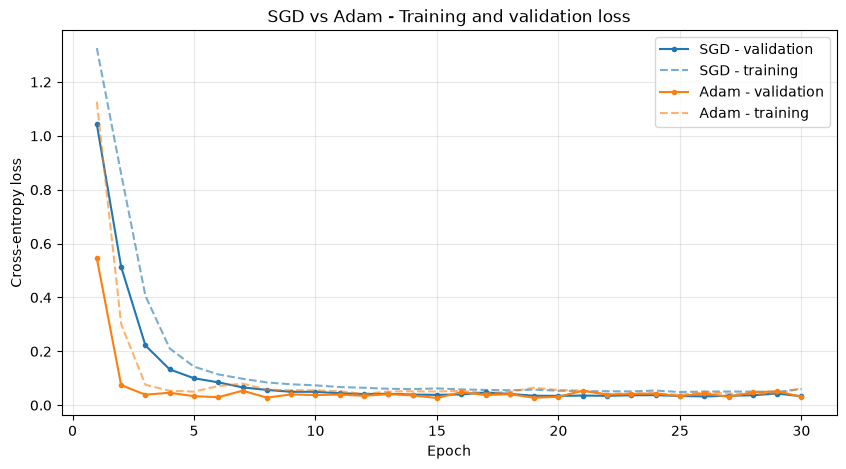

In [33]:
# ---------- Plot training and validation loss ----------
print("\n========== SGD vs Adam ==========")

epochs = range(1, 31)

plt.figure(figsize=(10, 5))

plt.plot(epochs, history_sgd["val_loss"], ".-", label="SGD - validation", color="tab:blue")
plt.plot(epochs, history_sgd["train_loss"], "--", label="SGD - training", color="tab:blue", alpha=0.6)

plt.plot(epochs, history_adam["val_loss"], ".-", label="Adam - validation", color="tab:orange")
plt.plot(epochs, history_adam["train_loss"], "--", label="Adam - training", color="tab:orange", alpha=0.6)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("SGD vs Adam - Training and validation loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [34]:
# ---------- Select the best model ----------
print("\n========== Best model ==========")

if history_sgd["val_loss"][-1] < history_adam["val_loss"][-1]:
    best_model = model_sgd
    best_name = "SGD"
    best_val_loss = history_sgd["val_loss"][-1]
else:
    best_model = model_adam
    best_name = "Adam"
    best_val_loss = history_adam["val_loss"][-1]

test_accuracy = compute_accuracy(best_model, test_loader)

print("Best optimizer:", best_name)
print(f"Final validation loss: {best_val_loss:.6f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")


========== Best model ==========
Best optimizer: Adam
Final validation loss: 0.031446
Test accuracy: 0.9667
Test accuracy (%): 96.67%


Both models were trained for 30 epochs using SGD and Adam. The training and validation losses decrease during training, showing that both models learn to classify the data. Adam achieved a lower final validation loss of 0.031446, so it was selected as the best model. Its test accuracy was 96.67%, which shows that it also performs well on unseen data.

In [35]:
import os 
# ---------- Save best model ----------
print("========== Save model ==========")

torch.save(best_model.state_dict(), "best_model.pth")
print("Saved model:", best_name)


# ---------- Load into new model ----------
print("\n========== Load model ==========")

new_model = MLP([2, 30, 20, 4])
new_model.load_state_dict(torch.load("best_model.pth", weights_only=True))

best_model.eval()
new_model.eval()


# ---------- Compare outputs ----------
print("\n========== Compare outputs ==========")

features, labels = next(iter(test_loader))

with torch.no_grad():
    output_original = best_model(features)
    output_loaded = new_model(features)

print("Original model output:", output_original[0])
print("Loaded model output:  ", output_loaded[0])

print("\nOutputs match:", torch.allclose(output_original, output_loaded))

os.remove("best_model.pth")

========== Save model ==========
Saved model: Adam

========== Load model ==========

========== Compare outputs ==========


Original model output: tensor([  0.7653,   9.7337, -10.2292,  -2.9361])
Loaded model output:   tensor([  0.7653,   9.7337, -10.2292,  -2.9361])

Outputs match: True


The best model's parameters were saved using `state_dict()` and loaded into a new MLP with the same architecture. Both models produced identical outputs for the same input data, which was confirmed using `torch.equal()`. The loaded model also achieved the same test accuracy, showing that the parameters were saved and restored correctly.

### 2.3 A count-based bigram model

Default text: `the-verdict.txt`. Tokens are characters; build the vocabulary from the whole text and use the last 10% for validation.

- Report training and validation perplexity for $\alpha \in \{0, 0.01, 0.1, 1, 10\}$ (report `inf` where it occurs) and explain both ends. On the default text, expect a validation perplexity of about 12 for $\alpha = 1$.
- Generate 200 characters from the $\alpha = 1$ model.

In [36]:
from pathlib import Path

# ---------- Read text ----------
text = Path("the-verdict.txt").read_text(encoding="utf-8")

# ---------- Vocabulary ----------
vocab = sorted(set(text))
V = len(vocab)

stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for ch, i in stoi.items()}

ids = torch.tensor([stoi[ch] for ch in text])

print("Text length:", len(text))
print("Vocabulary size:", V)


# ---------- Train and validation split ----------
split = int(0.9 * len(ids))

train_ids = ids[:split]
val_ids = ids[split:]

print("\n========== Data split ==========")
print("Training characters:", len(train_ids))
print("Validation characters:", len(val_ids))


# ---------- Count bigrams ----------
counts = torch.bincount(
    train_ids[:-1] * V + train_ids[1:],
    minlength=V * V
).view(V, V)


# ---------- Perplexity ----------
def perplexity(P, data):
    probs = P[data[:-1], data[1:]]

    if torch.any(probs == 0):
        return float("inf")

    return math.exp(-torch.log(probs).mean().item())


# ---------- Compare alpha values ----------
print("\n========== Perplexity comparison ==========")

print(f"{'Alpha':<10} {'Training PPL':>18} {'Validation PPL':>18}")
print("-" * 48)

for alpha in [0, 0.01, 0.1, 1, 10]:
    P = counts.double() + alpha
    row_sums = P.sum(dim=1, keepdim=True)
    P = torch.where(row_sums > 0, P / row_sums.clamp_min(1), torch.zeros_like(P))

    train_ppl = perplexity(P, train_ids)
    val_ppl = perplexity(P, val_ids)

    print(f"{alpha:<10} {train_ppl:>18.4f} {val_ppl:>18.4f}")

Text length: 20479
Vocabulary size: 62

========== Data split ==========
Training characters: 18431
Validation characters: 2048

========== Perplexity comparison ==========
Alpha            Training PPL     Validation PPL
------------------------------------------------
0                     10.8791                inf
0.01                  10.8971            11.0931
0.1                   11.0348            11.0236
1                     11.9549            11.7877
10                    17.1174            16.7567


The bigram model predicts the next character based only on the previous one. For alpha = 0, unseen bigrams have zero probability, which can lead to infinite validation perplexity. Adding smoothing gives unseen bigrams non-zero probabilities, but when alpha is too large, the probabilities become more uniform and the model loses information about the actual character frequencies. Lower perplexity means better predictions, so comparing training and validation perplexity helps us evaluate the effect of smoothing.

In [37]:
# ---------- Generate 200 characters (alpha = 1) ----------
print("========== Generated text ==========")

alpha = 1

P = (counts.double() + alpha)
P = P / P.sum(dim=1, keepdim=True)

g = torch.Generator().manual_seed(42)

current = stoi["T"]
generated = [itos[current]]

for i in range(199):
    current = torch.multinomial(P[current], 1, generator=g).item()
    generated.append(itos[current])

generated_text = "".join(generated)

print(generated_text)
print("\nNumber of characters:", len(generated_text))

========== Generated text ==========
Tharong--I)Thad hen ough-at sure as t.jbJzjpat ond I youtoshe y."Cr am, g yShLjThimitoulitan _T)ed;I't wavet l'thee, dOr-Apive rsamain w aiguice we, r fof be fUq
"I ibe are t we-le ge anevour larowato

Number of characters: 200


The model generates 200 characters using α = 1 and probabilities based on bigram counts. Some parts of the generated text look like English words, but most of the text does not make sense. This happens because the model only uses the previous character to predict the next one, without considering whole words or sentences. The smoothing also gives some probability to rare character pairs, so unusual combinations can appear.

### 2.4 A neural bigram model

- Train a table of logits $W \in \mathbb{R}^{V \times V}$ (`nn.Embedding(V, V)`) on the (current, next) character pairs with your `train` (default: batch size 256, Adam with learning rate 0.1, 5 epochs). Compare its validation perplexity with your best count-based model from Task 2.3 and explain the result.
- Compare the loss before training with $\ln V$. Explain the difference, and show that zero-initialised logits give exactly $\ln V$.
- Show with an experiment what plays the role of $\alpha$ (for example more epochs, or weight decay).

In [38]:
# ---------- Prepare data ----------
print("========== Prepare data ==========")

train_dataset = TensorDataset(train_ids[:-1], train_ids[1:])
val_dataset = TensorDataset(val_ids[:-1], val_ids[1:])

train_loader_bigram = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader_bigram = DataLoader(val_dataset, batch_size=256, shuffle=False)

print("Training pairs:", len(train_dataset))
print("Validation pairs:", len(val_dataset))
print("Vocabulary size:", V)


# ---------- Neural bigram model ----------
print("\n========== Neural bigram model ==========")

torch.manual_seed(42)

model_bigram = nn.Embedding(V, V)
optimizer_bigram = torch.optim.Adam(model_bigram.parameters(), lr=0.1)

print("Model:", model_bigram)
print("Parameters:", count_parameters(model_bigram))


# ---------- Train model ----------
print("\n========== Training ==========")

history_bigram = train(
    model_bigram,
    train_loader_bigram,
    val_loader_bigram,
    optimizer_bigram,
    num_epochs=5
)

print(f"Final training loss: {history_bigram['train_loss'][-1]:.6f}")
print(f"Final validation loss: {history_bigram['val_loss'][-1]:.6f}")


# ---------- Neural model perplexity ----------
print("\n========== Neural bigram perplexity ==========")

train_loss = compute_loss(model_bigram, train_loader_bigram)
val_loss = compute_loss(model_bigram, val_loader_bigram)

train_ppl_neural = math.exp(train_loss)
val_ppl_neural = math.exp(val_loss)

print(f"Training perplexity: {train_ppl_neural:.4f}")
print(f"Validation perplexity: {val_ppl_neural:.4f}")


# ---------- Best count-based model ----------
print("\n========== Best count-based model ==========")

best_alpha = None
best_count_ppl = float("inf")

for alpha in [0, 0.01, 0.1, 1, 10]:
    P = counts.double() + alpha
    P = P / P.sum(dim=1, keepdim=True).clamp_min(1)

    val_ppl = perplexity(P, val_ids)

    if val_ppl < best_count_ppl:
        best_count_ppl = val_ppl
        best_alpha = alpha

print("Best alpha:", best_alpha)
print(f"Validation perplexity: {best_count_ppl:.4f}")


# ---------- Comparison ----------
print("\n========== Perplexity comparison ==========")

print(f"{'Model':<22} {'Validation PPL':>16}")
print("-" * 40)
print(f"{'Count-based bigram':<22} {best_count_ppl:>16.4f}")
print(f"{'Neural bigram':<22} {val_ppl_neural:>16.4f}")

if val_ppl_neural < best_count_ppl:
    print("\nNeural bigram has lower validation perplexity.")
else:
    print("\nCount-based bigram has lower or equal validation perplexity.")


========== Prepare data ==========
Training pairs: 18430
Validation pairs: 2047
Vocabulary size: 62

========== Neural bigram model ==========
Model: Embedding(62, 62)
Parameters: 3844

========== Training ==========
Final training loss: 2.426539
Final validation loss: 2.421445

========== Neural bigram perplexity ==========
Training perplexity: 11.0707
Validation perplexity: 11.2621

========== Best count-based model ==========
Best alpha: 0.1
Validation perplexity: 11.0236

========== Perplexity comparison ==========
Model                    Validation PPL
----------------------------------------
Count-based bigram              11.0236
Neural bigram                   11.2621

Count-based bigram has lower or equal validation perplexity.


The neural bigram model was trained using an embedding table and Adam for 5 epochs. Unlike the count-based model, it learns its logits by updating the weights during training. The neural model achieved a validation perplexity of 11.2621, while the best count-based model achieved 11.0236 with α = 0.1. The count-based model performed slightly better, possibly because it directly estimates probabilities from bigram frequencies, while the neural model learns them approximately through optimization.

In [39]:
# ---------- Loss before training ----------
print("========== Loss before training ==========")

torch.manual_seed(42)
model_initial = nn.Embedding(V, V)

initial_loss = compute_loss(model_initial, train_loader_bigram)
expected_loss = math.log(V)

print(f"{'Random initialisation':<25} {initial_loss:.6f}")
print(f"{'ln(V)':<25} {expected_loss:.6f}")
print(f"{'Difference':<25} {initial_loss - expected_loss:.6f}")


# ---------- Zero-initialised logits ----------
print("\n========== Zero-initialised logits ==========")

model_zero = nn.Embedding(V, V).double()

with torch.no_grad():
    nn.init.zeros_(model_zero.weight)

zero_loss = compute_loss(model_zero, train_loader_bigram)

print(f"{'Zero-initialised loss':<25} {zero_loss:.10f}")
print(f"{'ln(V)':<25} {expected_loss:.10f}")
print("Values match:", math.isclose(zero_loss, expected_loss, rel_tol=0, abs_tol=1e-10))

========== Loss before training ==========
Random initialisation     4.595257
ln(V)                     4.127134
Difference                0.468123

========== Zero-initialised logits ==========
Zero-initialised loss     4.1271343850
ln(V)                     4.1271343850
Values match: True


Before training, the model has randomly initialised logits, so the predicted probabilities are not equal and the loss is usually higher than ln(V). When all logits are set to zero, softmax assigns the same probability 1/V to every character. Therefore, the cross-entropy is -log(1/V) = ln(V), which is confirmed by the calculated results.

In [40]:
# ---------- Experiment: epochs and weight decay ----------
print("========== Neural bigram experiment ==========")

results = []

settings = [
    ("5 epochs", 5, 0.0),
    ("30 epochs", 30, 0.0),
    ("Weight decay 0.1", 5, 0.1),
    ("Weight decay 1.0", 5, 1.0)
]

for name, epochs, wd in settings:
    torch.manual_seed(42)

    model = nn.Embedding(V, V)
    nn.init.zeros_(model.weight)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.1,
        weight_decay=wd
    )

    history = train(
        model,
        train_loader_bigram,
        val_loader_bigram,
        optimizer,
        num_epochs=epochs
    )

    train_ppl = math.exp(compute_loss(model, train_loader_bigram))
    val_ppl = math.exp(compute_loss(model, val_loader_bigram))

    results.append((name, train_ppl, val_ppl))


# ---------- Compare results ----------
print("\n========== Perplexity comparison ==========")
print(f"{'Experiment':<22} {'Training PPL':>15} {'Validation PPL':>17}")
print("-" * 56)

for name, train_ppl, val_ppl in results:
    print(f"{name:<22} {train_ppl:>15.4f} {val_ppl:>17.4f}")


========== Neural bigram experiment ==========

========== Perplexity comparison ==========
Experiment                Training PPL    Validation PPL
--------------------------------------------------------
5 epochs                       11.0682           11.2176
30 epochs                      11.0085           11.3890
Weight decay 0.1               58.4116           58.2527
Weight decay 1.0               61.6752           61.6692


Training for 30 epochs slightly decreases training perplexity, but increases validation perplexity, which may indicate overfitting. Increasing weight decay causes both training and validation perplexity to rise significantly. For weight decay = 1.0, perplexity is close to 62, which is the vocabulary size and the perplexity of a uniform distribution. This shows that weight decay has a similar effect to α in the count-based model, because stronger regularization makes the predicted probabilities more uniform.

### 2.5 Your own experiment

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 2.5.

========== Random initialization ==========

========== Constant initialization ==========

========== Comparison ==========
Model                        Validation loss     Accuracy
----------------------------------------------------------
Random initialization               0.038845       0.9833
Constant initialization             0.771842       0.6000


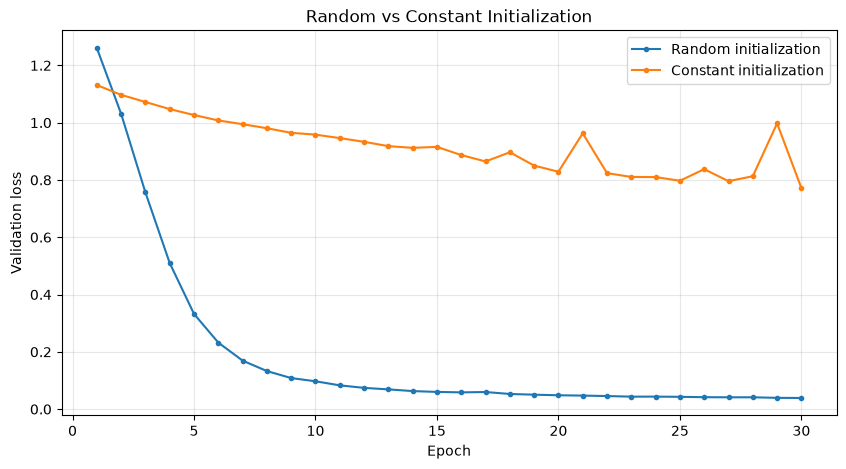

In [41]:
#Q: How does initializing all MLP weights to the same constant affect the model's learning 
#   and classification accuracy compared to random initialization?


# ---------- Random initialization ----------
print("========== Random initialization ==========")

torch.manual_seed(42)
model_random = MLP([2, 30, 20, 4])

optimizer_random = torch.optim.SGD(model_random.parameters(), lr=0.05)

history_random = train(
    model_random, train_loader, val_loader,
    optimizer_random, num_epochs=30
)

acc_random = compute_accuracy(model_random, val_loader)



# ---------- Constant initialization ----------
print("\n========== Constant initialization ==========")

torch.manual_seed(42)
model_constant = MLP([2, 30, 20, 4])

with torch.no_grad():
    for layer in model_constant.modules():
        if isinstance(layer, nn.Linear):
            layer.weight.fill_(0.1)
            layer.bias.zero_()

optimizer_constant = torch.optim.SGD(model_constant.parameters(), lr=0.05)

history_constant = train(
    model_constant, train_loader, val_loader,
    optimizer_constant, num_epochs=30
)

acc_constant = compute_accuracy(model_constant, val_loader)



# ---------- Comparison ----------
print("\n========== Comparison ==========")

print(f"{'Model':<25} {'Validation loss':>18} {'Accuracy':>12}")
print("-" * 58)

print(f"{'Random initialization':<25} {history_random['val_loss'][-1]:>18.6f} {acc_random:>12.4f}")
print(f"{'Constant initialization':<25} {history_constant['val_loss'][-1]:>18.6f} {acc_constant:>12.4f}")



# ---------- Plot validation loss ----------
epochs = range(1, 31)

plt.figure(figsize=(10, 5))

plt.plot(epochs, history_random["val_loss"], ".-", label="Random initialization")
plt.plot(epochs, history_constant["val_loss"], ".-", label="Constant initialization")

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Random vs Constant Initialization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The experiment shows that random initialization gives much better results than constant initialization. The randomly initialized model achieved 98.33% accuracy with a validation loss of 0.0388, while the model with constant weights (0.1) achieved only 60% accuracy with a loss of 0.7718. On the plot, the validation loss decreases much faster for random initialization, while the constant initialization model learns more slowly and its loss remains relatively high. This happens because random initialization breaks the symmetry between neurons, allowing them to learn different features. With constant initialization, neurons in the hidden layers remain identical, which limits the model's ability to learn.

In [42]:
# ---------- Different constant initializations ----------
print("========== Initialization experiment ==========")

results = []

for value in [0.0, 0.1, 0.5, 1.0]:
    torch.manual_seed(42)

    model = MLP([2, 30, 20, 4])

    with torch.no_grad():
        for layer in model.modules():
            if isinstance(layer, nn.Linear):
                layer.weight.fill_(value)
                layer.bias.zero_()

    optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

    history = train(
        model, train_loader, val_loader,
        optimizer, num_epochs=30
    )

    val_loss = history["val_loss"][-1]
    accuracy = compute_accuracy(model, val_loader)

    results.append((value, val_loss, accuracy))


# ---------- Comparison ----------
print(f"\n{'Initialization':<20} {'Validation loss':>18} {'Accuracy':>12}")
print("-" * 55)

print(f"{'Random':<20} {history_random['val_loss'][-1]:>18.6f} {acc_random:>12.4f}")

for value, loss, acc in results:
    print(f"{str(value):<20} {loss:>18.6f} {acc:>12.4f}")


========== Initialization experiment ==========

Initialization          Validation loss     Accuracy
-------------------------------------------------------
Random                         0.038845       0.9833
0.0                            1.390395       0.2583
0.1                            0.771842       0.6000
0.5                            0.978218       0.4417
1.0                            1.045275       0.4667


The second experiment compares different constant weight initialization values (0, 0.1, 0.5 and 1.0). Zero initialization gives the worst result, with only 25.83% accuracy, which is close to random guessing among four classes. This happens because zero weights and biases prevent the hidden layers from learning effectively with ReLU. Among the constant values, 0.1 gives the best accuracy (60%), while larger values lead to lower accuracy and higher validation loss. The results show that the choice of constant affects the model's performance, but increasing its value does not necessarily improve learning.